# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 1: Time and Frequency Domain, and the Pendulum
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. Signal Construction and Frequency Domain Analysis
We construct a signal composed of 5 Hz, 20 Hz, and 50 Hz sinusoids with seeded Gaussian noise ($N=1000, f_s=500$ Hz) and analyze its amplitude spectrum via Fast Fourier Transform (FFT).

=== Table 1.1: Sampling Parameters ===
Sampling frequency (fs): 500.0 Hz
Record length (T): 2.0 s
Time step (dt): 0.002 s
Number of samples (N): 1000
Frequency resolution (df): 0.5 Hz
Nyquist limit (fmax): 250.0 Hz

=== Table 1.2: Spectrum of the Constructed Signal ===
Component 1 | Set: 5.0 Hz, 1.00 V | Measured: 5.00 Hz, 0.9999 V
Component 2 | Set: 20.0 Hz, 0.50 V | Measured: 20.00 Hz, 0.5009 V
Component 3 | Set: 50.0 Hz, 0.25 V | Measured: 50.00 Hz, 0.2482 V


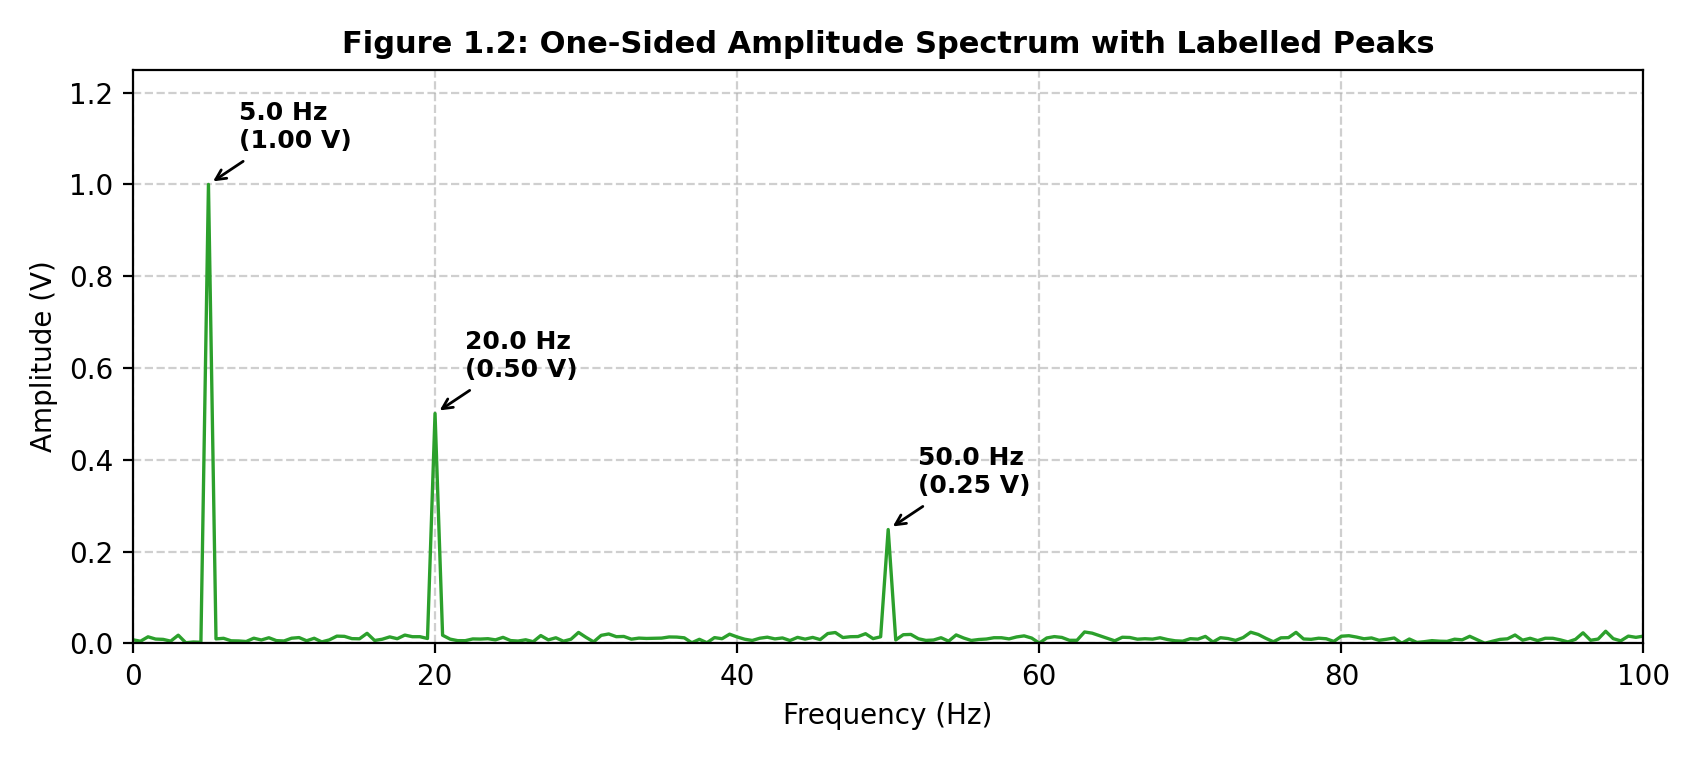

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import json

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp01-signals"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: Signal Construction and Frequency Domain Analysis
# -------------------------------------------------------------
fs = 500.0  # Sampling frequency in Hz
T = 2.0     # Signal record duration in seconds
dt = 1.0 / fs
t = np.arange(0, T, dt)
N = len(t)
df = fs / N
fmax = fs / 2.0

f1, f2, f3 = 5.0, 20.0, 50.0
A1, A2, A3 = 1.00, 0.50, 0.25

# Unique reproducible seed for student 500121985
rng = np.random.default_rng(174)
noise = 0.20 * rng.standard_normal(N)
x = A1 * np.sin(2 * np.pi * f1 * t) + A2 * np.sin(2 * np.pi * f2 * t) + A3 * np.sin(2 * np.pi * f3 * t) + noise

# Compute one-sided amplitude spectrum
X = np.fft.rfft(x)
freqs = np.fft.rfftfreq(N, d=dt)
amp = np.abs(X) * 2.0 / N
amp[0] /= 2.0

def measure_peak(f_target):
    idx = np.argmin(np.abs(freqs - f_target))
    window = range(max(0, idx - 2), min(len(freqs), idx + 3))
    peak_idx = max(window, key=lambda i: amp[i])
    return freqs[peak_idx], amp[peak_idx]

p1_f, p1_a = measure_peak(5.0)
p2_f, p2_a = measure_peak(20.0)
p3_f, p3_a = measure_peak(50.0)

print("=== Table 1.1: Sampling Parameters ===")
print(f"Sampling frequency (fs): {fs} Hz")
print(f"Record length (T): {T} s")
print(f"Time step (dt): {dt} s")
print(f"Number of samples (N): {N}")
print(f"Frequency resolution (df): {df} Hz")
print(f"Nyquist limit (fmax): {fmax} Hz")

print("\n=== Table 1.2: Spectrum of the Constructed Signal ===")
print(f"Component 1 | Set: {f1:.1f} Hz, {A1:.2f} V | Measured: {p1_f:.2f} Hz, {p1_a:.4f} V")
print(f"Component 2 | Set: {f2:.1f} Hz, {A2:.2f} V | Measured: {p2_f:.2f} Hz, {p2_a:.4f} V")
print(f"Component 3 | Set: {f3:.1f} Hz, {A3:.2f} V | Measured: {p3_f:.2f} Hz, {p3_a:.4f} V")

# Figure 1.1: Constructed Signal in Time Domain
plt.figure(figsize=(8.5, 3.6), dpi=200)
plt.plot(t[:250], x[:250], color='#1f77b4', lw=1.2, label='Constructed signal (first 0.5 s)')
plt.title('Figure 1.1: Constructed Signal in the Time Domain (fs = 500 Hz, N = 1000)', fontsize=11, fontweight='bold')
plt.xlabel('Time (s)', fontsize=10)
plt.ylabel('Amplitude (V)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig1_1_signal.png"))
plt.close()

# Figure 1.2: Amplitude Spectrum
plt.figure(figsize=(8.5, 3.8), dpi=200)
plt.plot(freqs, amp, color='#2ca02c', lw=1.2, label='Amplitude Spectrum')
plt.xlim(0, 100)
plt.ylim(0, max(amp) * 1.25)
plt.title('Figure 1.2: One-Sided Amplitude Spectrum with Labelled Peaks', fontsize=11, fontweight='bold')
plt.xlabel('Frequency (Hz)', fontsize=10)
plt.ylabel('Amplitude (V)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
for pf, pa in [(p1_f, p1_a), (p2_f, p2_a), (p3_f, p3_a)]:
    plt.annotate(f'{pf:.1f} Hz\n({pa:.2f} V)', xy=(pf, pa), xytext=(pf + 2, pa + 0.08),
                 arrowprops=dict(facecolor='black', arrowstyle='->', lw=1),
                 fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig1_2_spectrum.png"))
plt.close()



### 2. Demonstration of Aliasing
A 5.0 Hz sine wave sampled at 8.0 Hz violates the Nyquist condition ($f_s < 2f$). It folds across the Nyquist limit (4.0 Hz) and appears as an alias at $|8.0 - 5.0| = 3.0$ Hz.

Aliasing demonstrated: 5 Hz sine sampled at 8 Hz appears at |8 - 5| = 3 Hz.


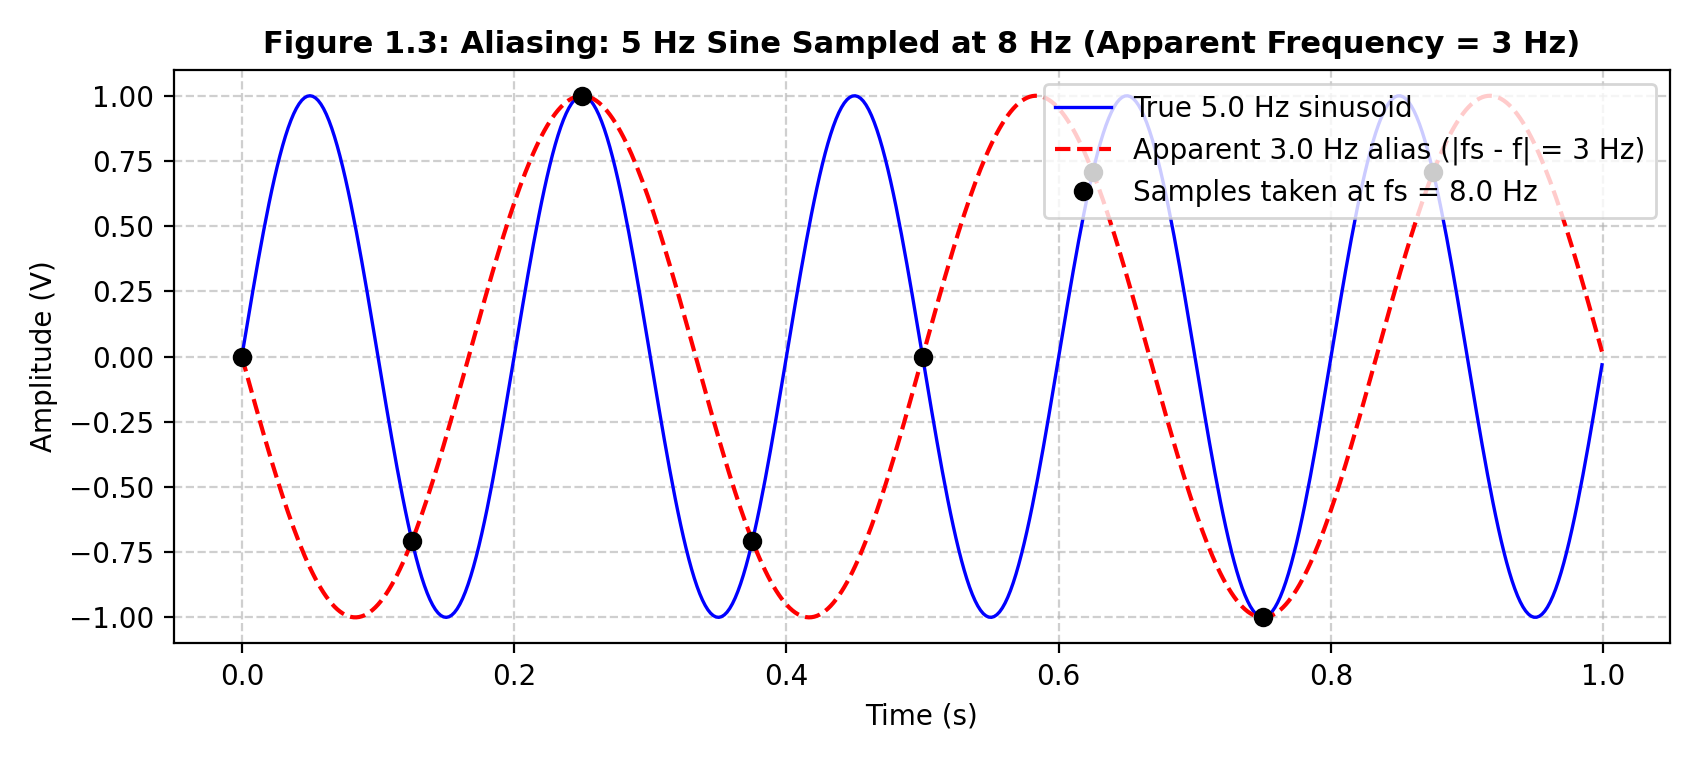

In [2]:
# Figure 1.3: Aliasing (5 Hz sine sampled at 8 Hz)
t_cont = np.linspace(0, 2.0, 1000)
sig_cont = np.sin(2 * np.pi * 5.0 * t_cont)
fs_alias = 8.0
t_sampled = np.arange(0, 2.0, 1.0 / fs_alias)
sig_sampled = np.sin(2 * np.pi * 5.0 * t_sampled)
# Aliased frequency |8 - 5| = 3 Hz, with phase matching sampled points
sig_alias_reconstructed = np.sin(2 * np.pi * 3.0 * t_cont + np.pi)

plt.figure(figsize=(8.5, 3.8), dpi=200)
plt.plot(t_cont[:500], sig_cont[:500], 'b-', lw=1.2, label='True 5.0 Hz sinusoid')
plt.plot(t_cont[:500], sig_alias_reconstructed[:500], 'r--', lw=1.5, label='Apparent 3.0 Hz alias (|fs - f| = 3 Hz)')
plt.plot(t_sampled[:8], sig_sampled[:8], 'ko', ms=6, label='Samples taken at fs = 8.0 Hz')
plt.title('Figure 1.3: Aliasing: 5 Hz Sine Sampled at 8 Hz (Apparent Frequency = 3 Hz)', fontsize=11, fontweight='bold')
plt.xlabel('Time (s)', fontsize=10)
plt.ylabel('Amplitude (V)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig1_3_aliasing.png"))
plt.close()

# -------------------------------------------------------------


### 3. Pendulum Motion Simulation and Viscous Damping
We formulate the pendulum equation as a first-order system $\dot{\theta} = \omega, \dot{\omega} = -b\omega - (g/L)\sin\theta$ and solve using `scipy.integrate.solve_ivp` across three damping regimes.

Theoretical small-angle period T0 = 2*pi*sqrt(L/g) = 2.0061 s


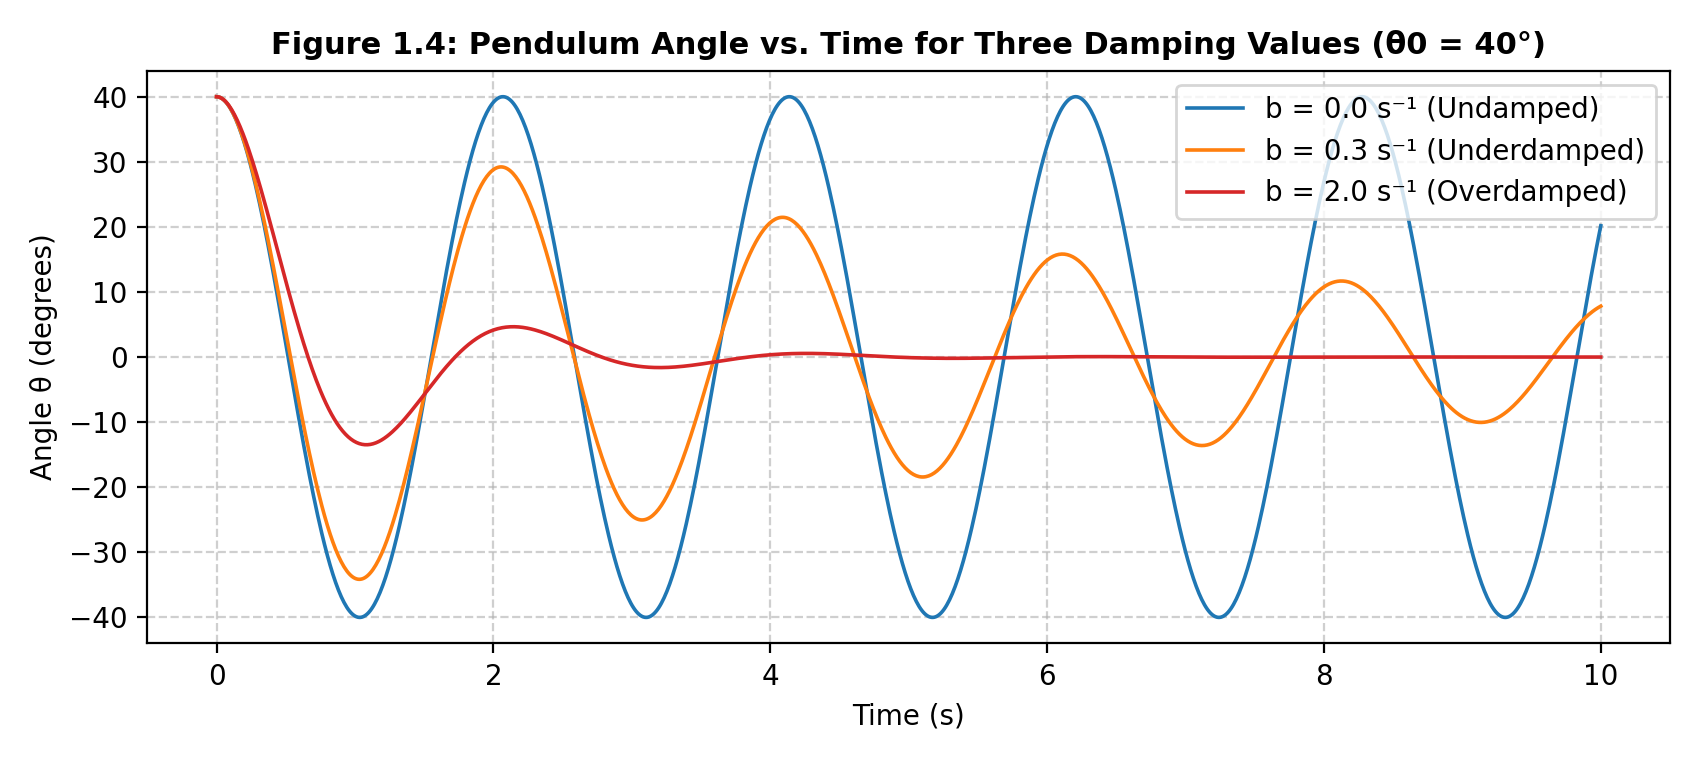

In [3]:
# Part 2: Pendulum Motion Simulation and Damping
# -------------------------------------------------------------
g = 9.81
L = 1.0
T0 = 2 * np.pi * np.sqrt(L / g)
print(f"\nTheoretical small-angle period T0 = 2*pi*sqrt(L/g) = {T0:.4f} s")

def pendulum_ode(t, y, b):
    theta, omega = y
    return [omega, -b * omega - (g / L) * np.sin(theta)]

theta0_deg = 40.0
theta0_rad = np.radians(theta0_deg)
t_eval = np.linspace(0, 10.0, 1000)

plt.figure(figsize=(8.5, 3.8), dpi=200)
damping_configs = [
    (0.0, '#1f77b4', 'b = 0.0 s⁻¹ (Undamped)'),
    (0.3, '#ff7f0e', 'b = 0.3 s⁻¹ (Underdamped)'),
    (2.0, '#d62728', 'b = 2.0 s⁻¹ (Overdamped)')
]
for b_val, col, lbl in damping_configs:
    sol = solve_ivp(pendulum_ode, [0, 10.0], [theta0_rad, 0.0], args=(b_val,), t_eval=t_eval, rtol=1e-8, atol=1e-8)
    plt.plot(sol.t, np.degrees(sol.y[0]), color=col, lw=1.3, label=lbl)

plt.title('Figure 1.4: Pendulum Angle vs. Time for Three Damping Values (θ0 = 40°)', fontsize=11, fontweight='bold')
plt.xlabel('Time (s)', fontsize=10)
plt.ylabel('Angle θ (degrees)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig1_4_damped.png"))
plt.close()

# -------------------------------------------------------------


### 4. Phase Portrait and Nonlinear Period Divergence
For large initial amplitudes, $\sin\theta \approx \theta$ fails. We sweep $\theta_0$ from $5^\circ$ to $175^\circ$ and measure the nonlinear period increase using positive zero crossings and FFT.

=== Table 1.3: Measured Period Against Initial Amplitude ===
θ0 =   5.0° | T_zc = 2.0070 s | T_fft = 2.0002 s | Ratio T/T0 = 1.000
θ0 =  20.0° | T_zc = 2.0215 s | T_fft = 2.0002 s | Ratio T/T0 = 1.008
θ0 =  40.0° | T_zc = 2.0689 s | T_fft = 2.0691 s | Ratio T/T0 = 1.031
θ0 =  60.0° | T_zc = 2.1529 s | T_fft = 2.1430 s | Ratio T/T0 = 1.073
θ0 =  80.0° | T_zc = 2.2819 s | T_fft = 2.3079 s | Ratio T/T0 = 1.137
θ0 =  95.0° | T_zc = 2.4174 s | T_fft = 2.4002 s | Ratio T/T0 = 1.205
θ0 = 120.0° | T_zc = 2.7541 s | T_fft = 2.7275 s | Ratio T/T0 = 1.373
θ0 = 140.0° | T_zc = 3.1986 s | T_fft = 3.1582 s | Ratio T/T0 = 1.594
θ0 = 160.0° | T_zc = 4.0272 s | T_fft = 4.0003 s | Ratio T/T0 = 2.008
θ0 = 175.0° | T_zc = 5.7728 s | T_fft = 6.0005 s | Ratio T/T0 = 2.878


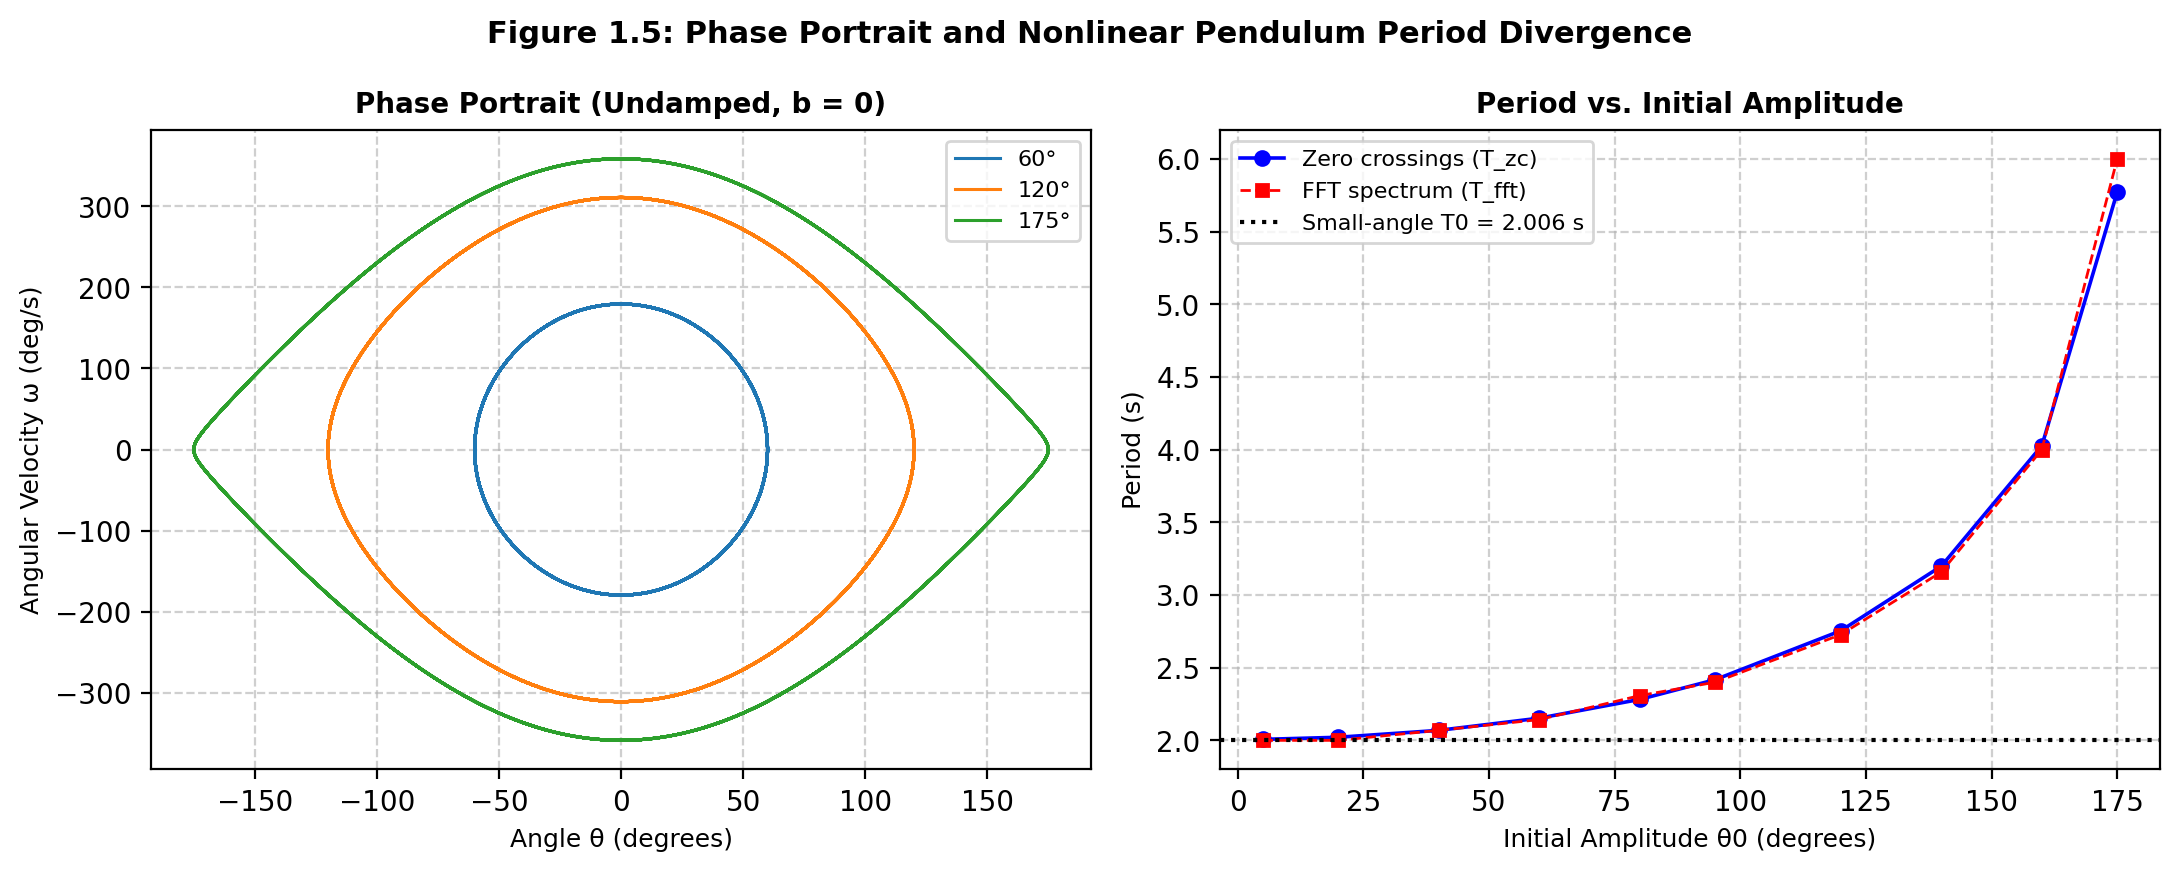

In [4]:
# Part 3: Phase Portrait & Period vs Initial Amplitude
# -------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), dpi=200)

sweep_angles = [5.0, 20.0, 40.0, 60.0, 80.0, 95.0, 120.0, 140.0, 160.0, 175.0]
zc_periods = []
fft_periods = []

for ang in sweep_angles:
    th0 = np.radians(ang)
    t_ev = np.linspace(0, 60.0, 12000)
    sol = solve_ivp(pendulum_ode, [0, 60.0], [th0, 0.0], args=(0.0,), t_eval=t_ev, rtol=1e-9, atol=1e-9)
    th_deg = np.degrees(sol.y[0])
    omega_deg = np.degrees(sol.y[1])

    if ang in [30.0, 60.0, 90.0, 120.0, 150.0, 175.0]:
        ax1.plot(th_deg, omega_deg, lw=1.1, label=f'{int(ang)}°')

    # Measure period via interpolated positive zero crossings
    th_v = sol.y[0]
    crossings = []
    for i in range(len(th_v) - 1):
        if th_v[i] <= 0 and th_v[i+1] > 0:
            t_c = sol.t[i] - th_v[i] * (sol.t[i+1] - sol.t[i]) / (th_v[i+1] - th_v[i])
            crossings.append(t_c)
    t_zc = np.mean(np.diff(crossings))
    zc_periods.append(t_zc)

    # Measure period via FFT peak
    th_fft = np.fft.rfft(th_v)
    th_f = np.fft.rfftfreq(len(th_v), d=(sol.t[1] - sol.t[0]))
    idx_p = 1 + np.argmax(np.abs(th_fft[1:]))
    t_fft = 1.0 / th_f[idx_p]
    fft_periods.append(t_fft)

ax1.set_title('Phase Portrait (Undamped, b = 0)', fontsize=10, fontweight='bold')
ax1.set_xlabel('Angle θ (degrees)', fontsize=9)
ax1.set_ylabel('Angular Velocity ω (deg/s)', fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', fontsize=8)

ax2.plot(sweep_angles, zc_periods, 'bo-', ms=5, lw=1.3, label='Zero crossings (T_zc)')
ax2.plot(sweep_angles, fft_periods, 'rs--', ms=4, lw=1.0, label='FFT spectrum (T_fft)')
ax2.axhline(T0, color='k', linestyle=':', label=f'Small-angle T0 = {T0:.3f} s')
ax2.set_title('Period vs. Initial Amplitude', fontsize=10, fontweight='bold')
ax2.set_xlabel('Initial Amplitude θ0 (degrees)', fontsize=9)
ax2.set_ylabel('Period (s)', fontsize=9)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper left', fontsize=8)

plt.suptitle('Figure 1.5: Phase Portrait and Nonlinear Pendulum Period Divergence', fontsize=11, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig1_5_phase_period.png"), bbox_inches='tight')
plt.close()

print("\n=== Table 1.3: Measured Period Against Initial Amplitude ===")
for ang, tzc, tfft in zip(sweep_angles, zc_periods, fft_periods):
    print(f"θ0 = {ang:5.1f}° | T_zc = {tzc:.4f} s | T_fft = {tfft:.4f} s | Ratio T/T0 = {tzc/T0:.3f}")
